# Airbus data tracking: order sheet vs CSDA STAC and ADAPT

Which Airbus acquisitions at the sites of the On-Ramp 2 order tracking sheet (`AirbusTracking` tab) are in CSDA STAC, what is
their order status, and are they on ADAPT?

## What this notebook gives you

Run it top to bottom. It ends with the same three results as the other tracking notebook
(`vantor_legion_supp_tracking.ipynb`), in section 8:

| Result | Section | Where to find it |
|---|---|---|
| **1. What is new** in CSDA STAC since the last run | 5 | `new`, and section 8 |
| **2. The HTML summary** of what is available | 6 | `SUMMARY_HTML`, linked from the timeline |
| **3. New data on ADAPT**: anything in CSDA STAC that is not on ADAPT yet is downloaded | 7 | `DOWNLOAD_DIR` |

| Section | What it does | Output |
|---|---|---|
| 1. What was requested | reads the tracking sheet | `tracking`: one row per site, Acq #, platform and TOA/SR column, with its status |
| 2. Search CSDA STAC | every `airbus-optical` product at the tracked sites | `res.gdf`, `csda_acqs` |
| 3. What is on ADAPT | checks each product | `products` |
| 4. Compare with the request | matches the sheet, fills the new tasking slots, shows what changed since `SINCE`, writes the Excel copy | `tracking`, `in_csda_gdf`, `since_summary` |
| 5. New since the last run | compares with the list saved by the last run | `products.new`, `new` |
| 6. HTML summary | per-site table of what is available | `SUMMARY_HTML`, `site_table` |
| 7. Download | fetches the products not on ADAPT; `DO_DOWNLOAD = False` only plans | `plan`, `check` |
| 8. Results | updates the page after the download, saves this run, prints the three results | `OUT_DIR/runs/` |

Sections 2, 3 and 5 to 8 work the same way in both notebooks (`lib/tracking_report.py`); only sections 1 and 4 are about Airbus.

**What the words mean**

- **Available**: in CSDA STAC at the tracked sites. Section 2 always searches afresh, with no cache.
- **Acquisition**: one satellite collect (Airbus acquisition / datastrip ID). **Product**: one catalog item of it (for example pan or MS, TOA or SR).
- **New**: a product that was not in the list saved by the last run (`OUT_DIR/runs/products_YYYYMMDD.csv`). CSDA STAC does
  not record when an item was added, so this is how late deliveries of old acquisitions are found. The last run is the latest
  one before today, so running again the same day gives the same answer.
- **On ADAPT**: checked per product, so a new version of an acquisition already on ADAPT is still fetched. A product is on ADAPT
  if a folder `<dir>/<item id>/` in `ALREADY_HAVE_DIRS` holds all of its assets, or it is in `LOCAL_FOOTPRINTS`
  (from `footprint_CSDA_eval_all_data.ipynb`; rerun that after a download).

Runs in the **ILAB DEV kernel** (where `csda_client` is installed).

**About the sheet**

**Status comes from the cell fill colour**, read against the sheet's legend (rows 1-2): Archive Order
Needed / Submitted / Received, Archive to be considered if allocation exists, New Tasking Needed /
Submitted / Received. Black cells are `n/a (black)`; cells with no fill (e.g. most of the SPOT-6 column) are `unmarked`.

**Matching is by platform and acquisition time, at the same site.** The sheet gives PHR/SPOT as datastrip
IDs (`DS_PHR1A_202304050917383_...`, time to 0.1 s) and PNeo as a date + `ACQ_` ID; CSDA item IDs start with
the platform and time (`PNEO4_202305100917387_PAN_ORT_RFL`). PHR matches to the 0.1 s; PNeo dates are
within ~1-3 s of the CSDA ID. A match within `MATCH_SECONDS` is `match='id time'`; within `PASS_SECONDS`
it is `'same pass?'` (e.g. SPOT-6 datastrip start vs. scene time, ~17 s): check those.

Library: `lib/tracking_report.py` (the three results), `lib/order_tracking.py` (sheet reader), `lib/multistac.py` (search).

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
from pathlib import Path
import pandas as pd
import geopandas as gpd
from IPython.display import Markdown
import multistac, multistac_plots, order_tracking, tracking_report
for m in (multistac, multistac_plots, order_tracking, tracking_report):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 200)

## Parameters

In [2]:
VENDOR = 'Airbus'
SITES = '/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi.geojson'
SITE_NAME_FIELD = 'Site Name'
SITE_ALIASES = {'Libya 4': 'PICS Libya-4'}   # tracking-sheet name -> name in the sites file
START, END = '2012-01-01', pd.Timestamp.today().strftime('%Y-%m-%d')   # Pleiades 1A launched Dec 2011
PROVIDERS = {'csda': ['airbus-optical']}
SINCE = '2026-09-01'                         # section 4d summary: images acquired on or after this date

# What was requested
TRACKING_XLSX = '/home/pmontesa/code/csda_summaries/sites/OnRamp2_OrderTracking_August2026.xlsx'
TRACKING_SHEET = 'AirbusTracking'
MATCH_SECONDS = 5     # CSDA acquisition within this of the sheet's time = the same acquisition
PASS_SECONDS = 120    # within this = probably the same pass (flagged 'same pass?' to check)
TASKING_SINCE = '2026-08-01'                 # new tasking submitted (On-Ramp 2, Aug 2026): later CSDA acquisitions can fill its slots
NEW_TASKING_STATUS = 'New Tasking Submitted'  # sheet status of the slots waiting for a tasked acquisition

# ADAPT
LOCAL_FOOTPRINTS = '/explore/nobackup/projects/CSDA_eval/footprints/footprints_CSDA_eval_ACQUISITIONS_latest.csv'   # one row per local product
DOWNLOAD_DIR = Path('/explore/nobackup/projects/CSDA_eval/Data/Airbus/augmentation')
ALREADY_HAVE_DIRS = [Path('/explore/nobackup/projects/CSDA_eval/Data/Airbus'), DOWNLOAD_DIR]   # <dir>/<item id>/ = already downloaded
PRODUCTS_CSV = DOWNLOAD_DIR / 'onramp2_tracked_products.csv'   # site and acquisition of each downloaded product

# Results
OUT_DIR = '/explore/nobackup/people/pmontesa/multistac/airbus_order_tracking'   # OUT_DIR/runs/ keeps each run's product list
SUMMARY_HTML = '/home/pmontesa/code/csda_summaries/html/augmentation/airbus_augmentation_summary.html'

# Download (section 7)
DO_DOWNLOAD = True       # False: plan only
DOWNLOAD_ALL = True      # True: every asset (images + sidecars). False: metadata only
MAX_WORKERS = 8
CREDENTIALS_FILE = '/home/pmontesa/code/credentials.ini'


## 1. What was requested: the tracking sheet

One row per filled cell: `acq_time` comes from the DS_ ID (PHR, SPOT) or the PNeo date column. Empty cells
that carry a status (e.g. a *New Tasking Submitted* slot with no acquisition yet) are kept with no `tracking_id`.

In [3]:
tracking = order_tracking.read_airbus_tracking(TRACKING_XLSX, TRACKING_SHEET, site_aliases=SITE_ALIASES)
print(f"{len(tracking)} tracked cells, {tracking.tracking_id.notna().sum()} with an ID, "
      f"{tracking.acq_time.notna().sum()} with an acquisition time")
tracking.head(10)

281 tracked cells, 179 with an ID, 170 with an acquisition time


,site_name,acq_num,platform,radiometry,status,tracking_id,acq_time,sheet_note,cell,cells
0,Gobabeb,1,PHR1A,TOA,Archive Order Submitted,DS_PHR1A_202304050917383_FR1_PX_E015S24_0110_0...,2023-04-05 09:17:38.300000+00:00,CSDA has 3 scenes,C6,C6
1,Gobabeb,1,PHR1B,TOA,Archive Order Submitted,DS_PHR1B_202508160921429_FR1_PX_E015S24_0210_0...,2025-08-16 09:21:42.900000+00:00,CSDA has 3 scenes,E6,E6
2,Gobabeb,1,PNEO3,TOA,Archive Order Submitted,ACQ_PNEO3_02908906927283,2023-05-02 09:13:59.581000+00:00,CSDA has 3 scenes,G6,G6 H6
3,Gobabeb,1,PNEO4,TOA,Archive Order Submitted,ACQ_PNEO4_02901507036755,2023-05-10 09:17:38.338000+00:00,CSDA has 3 scenes,J6,J6 K6
4,Gobabeb,1,SPOT6,TOA,unmarked,DS_SPOT6_202305020844290_FR1_FR1_FR1_FR1_E015S...,2023-05-02 08:44:29+00:00,None,M6,M6
5,Gobabeb,2,PHR1A,TOA,Archive Order Submitted,DS_PHR1A_202604270917524_FR1_PX_E015S24_0110_0...,2026-04-27 09:17:52.400000+00:00,CSDA has 3 scenes,C7,C7
6,Gobabeb,2,PNEO3,TOA,Archive Order Submitted,ACQ_PNEO3_03208908006809,2023-07-19 09:14:16.459000+00:00,CSDA has 3 scenes,G7,G7 H7
7,Gobabeb,2,PNEO4,TOA,Archive Order Submitted,ACQ_PNEO4_03008907468219,2023-06-10 09:14:11.706000+00:00,CSDA has 3 scenes,J7,J7 K7
8,Gobabeb,2,SPOT6,TOA,unmarked,DS_SPOT6_202309090844195_FR1_FR1_FR1_FR1_E015S...,2023-09-09 08:44:19.500000+00:00,None,M7,M7
9,Gobabeb,3,PHR1A,TOA,Archive to be considered if allocation exists,DS_PHR1A_202404030917218_FR1_PX_E015S24_0110_0...,2024-04-03 09:17:21.800000+00:00,CSDA has 3 scenes,C8,C8


In [4]:
# Status of every tracked cell, by platform and TOA/SR column
tracking.groupby(['platform', 'radiometry', 'status']).size().unstack(['platform', 'radiometry'], fill_value=0)

platform                                      PHR1A     PHR1B     PNEO3     PNEO4     SPOT6    
radiometry                                       SR TOA    SR TOA    SR TOA    SR TOA    SR TOA
status                                                                                         
Archive Order Needed                              0   0     0   1     0   0     0   0     0   0
Archive Order Submitted                           0  16     0  14     1  18     3  20     0   0
Archive to be considered if allocation exists     0   8     0   6     0   0     0   0     0   0
New Tasking Needed                                0   0     0   0     0   0     0   0     4   5
New Tasking Submitted                             0  10     0  13    15  21    13  21     0   0
n/a (black)                                       8   0     3   0     1   0     8   0     8   0
unmarked                                          0   0     0   0     0   0     0   0    14  50

## 2. Search CSDA STAC

In [5]:
sites = multistac.load_sites(SITES, site_name_field=SITE_NAME_FIELD)
sites = sites[sites.site_name.isin(tracking.site_name.unique())]
missing = sorted(set(tracking.site_name) - set(sites.site_name))
if missing:
    print('Tracking sites not in the sites file (add to SITE_ALIASES):', missing)
print(len(sites), 'sites:', ', '.join(sites.site_name))

8 sites: Baotou, Gobabeb, La Crau, PICS Libya-4, Railroad Valley, Valencia, WLEF, Golmud


In [6]:
%%time
res = multistac.search(sites, START, END, PROVIDERS)   # no cache_dir: always a fresh search, so new deliveries are found
print(res)
res.log[res.log.status == 'failed']

searches:   0%|          | 0/8 [00:00<?, ?it/s]

searches:  12%|█▎        | 1/8 [00:00<00:02,  3.50it/s]

searches:  38%|███▊      | 3/8 [00:00<00:00,  8.87it/s]

searches:  62%|██████▎   | 5/8 [00:00<00:00,  9.06it/s]

searches:  62%|██████▎   | 5/8 [00:19<00:00,  9.06it/s]

searches: 100%|██████████| 8/8 [02:00<00:00, 20.99s/it]

searches: 100%|██████████| 8/8 [02:00<00:00, 15.05s/it]

SearchResult(502 rows, 502 unique items, 0 failed tasks)
CPU times: user 417 ms, sys: 67.4 ms, total: 484 ms
Wall time: 2min 1s


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds


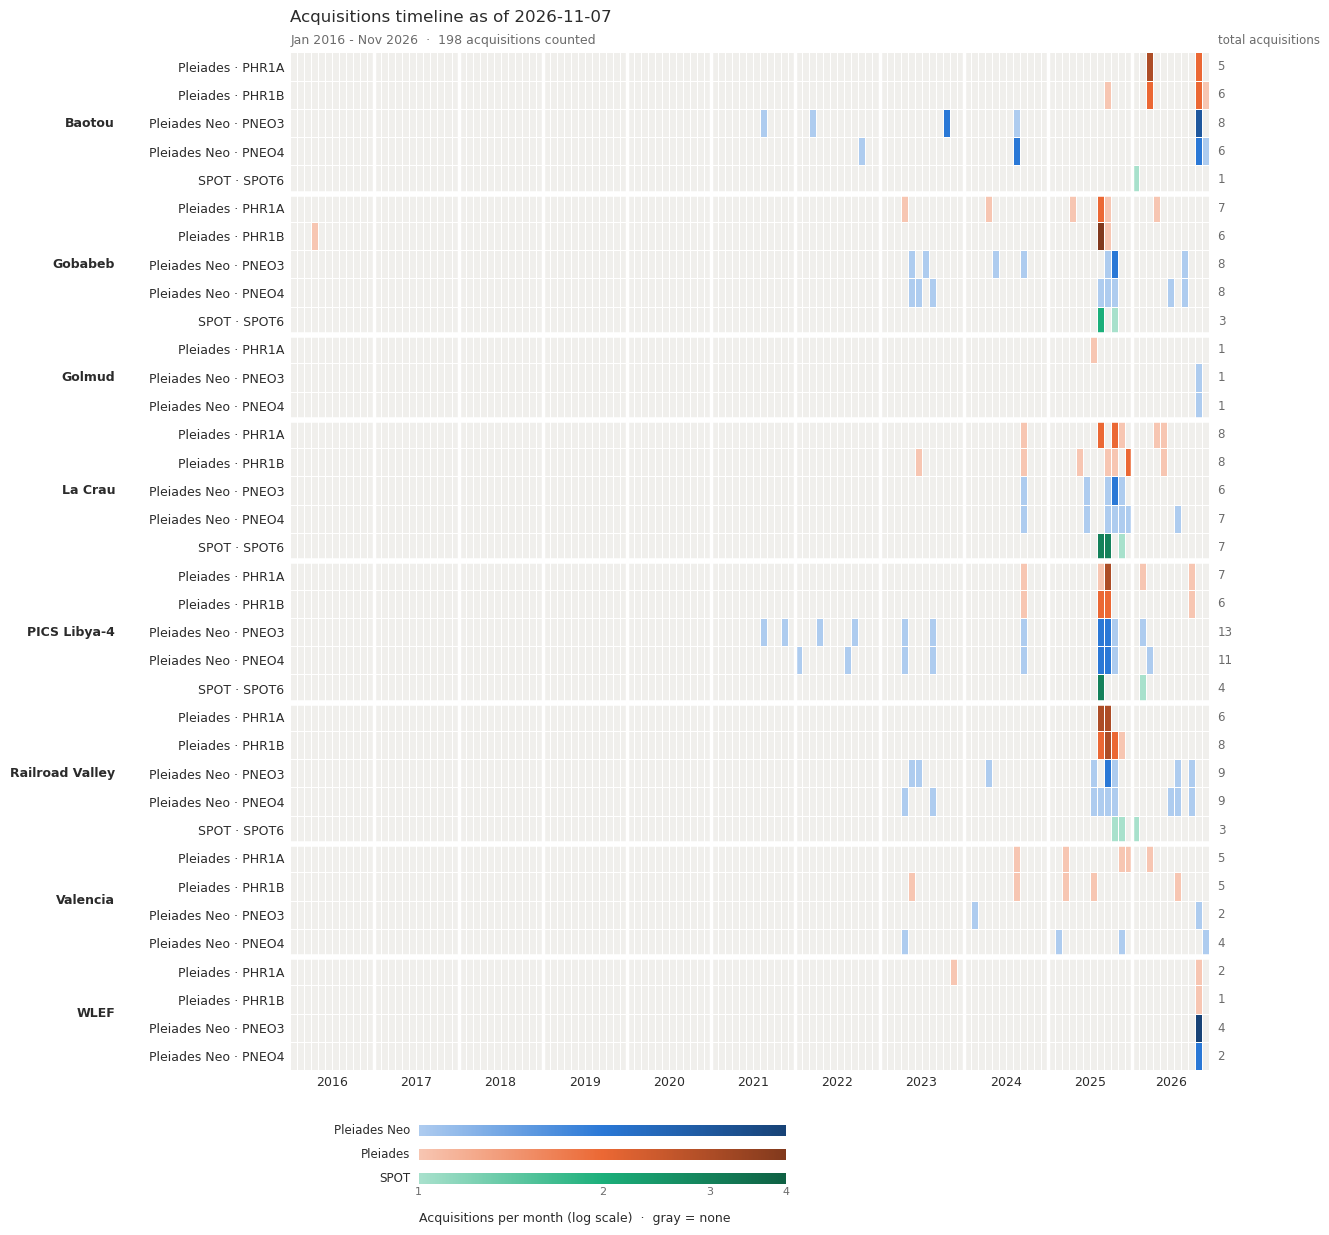

In [7]:
# Acquisitions: how often each site group was imaged (products of one collect counted once)
multistac_plots.plot_month_heatmap(res.by_month(['site_name','constellation','sensor'], count='acquisitions'), color_by='constellation', max_rows=None,
                                   title=f'Acquisitions timeline as of {END}');

In [8]:
# Platform, acquisition time and radiometry of each CSDA product (time from the item ID, as in the sheet)
csda = res.gdf.copy()
parsed = csda['id'].map(order_tracking.id_time)
csda['platform_id'] = [p for p, t in parsed]
csda['acq_time'] = [t for p, t in parsed]
csda['radiometry'] = (csda['airbus-optical:radiometric_processing']
                      .map({'REFLECTANCE': 'TOA', 'SURFACE_REFLECTANCE': 'SR', 'BASIC': 'basic'})
                      .fillna(csda['airbus-optical:radiometric_processing']))

# One row per CSDA acquisition and site
csda_acqs = (csda.dropna(subset=['acq_time'])
             .groupby(['site_name', 'platform_id', 'acquisition_id'], as_index=False)
             .agg(csda_time=('acq_time', 'first'), n_products=('id', 'nunique'),
                  csda_radiometry=('radiometry', lambda s: ', '.join(sorted(s.dropna().unique())))))
csda_acqs.groupby(['site_name', 'platform_id']).size().unstack(fill_value=0)

platform_id,PHR1A,PHR1B,PNEO3,PNEO4,SPOT6
site_name,,,,,
Baotou,5,6,8,6,1
Gobabeb,7,6,8,8,3
Golmud,1,0,1,1,0
La Crau,8,8,6,7,7
PICS Libya-4,7,6,13,11,4
Railroad Valley,6,8,9,9,3
Valencia,5,5,2,4,0
WLEF,2,1,4,2,0


## 3. What is on ADAPT

`products`: one row per CSDA product and site, with `on_adapt`. The check is explained at the top of this notebook.

In [9]:
bands = res.gdf.product_type.map({'P': 1, 'PAN': 1, 'MS': 4, 'MS-FS': 6})
products = tracking_report.products_table(res.gdf, radiometry=csda.radiometry, bands=bands)
local_copies = tracking_report.airbus_local_copies(products, LOCAL_FOOTPRINTS, MATCH_SECONDS)
products = tracking_report.mark_on_adapt(products, res.items, ALREADY_HAVE_DIRS, local_copies)
print(f"{products[products.on_adapt].id.nunique()} of {products.id.nunique()} CSDA products on ADAPT")
tracking_report.acquisitions_table(products).groupby('site_name').agg(acquisitions=('acquisition_id', 'size'), on_adapt=('on_adapt', 'sum'))

484 of 502 CSDA products on ADAPT


,acquisitions,on_adapt
site_name,,
Baotou,26,21
Gobabeb,32,32
Golmud,3,3
La Crau,36,36
PICS Libya-4,41,41
Railroad Valley,35,35
Valencia,16,15
WLEF,9,8


## 4. Compare with the request

### 4a. Match the sheet to CSDA

Nearest CSDA acquisition of the same platform at the same site, within `PASS_SECONDS`.
`radiometry_in_csda` says whether CSDA has the sheet column's radiometry (TOA = `REFLECTANCE`, SR = `SURFACE_REFLECTANCE`).

In [10]:
timed = tracking.dropna(subset=['acq_time']).reset_index().sort_values('acq_time')
nearest = pd.merge_asof(timed, csda_acqs.rename(columns={'platform_id': 'platform'}).sort_values('csda_time'),
                        left_on='acq_time', right_on='csda_time', by=['site_name', 'platform'],
                        tolerance=pd.Timedelta(seconds=PASS_SECONDS), direction='nearest').set_index('index')

tracking = tracking.join(nearest[['acquisition_id', 'csda_time', 'n_products', 'csda_radiometry']])
tracking['dt_seconds'] = (tracking.csda_time - tracking.acq_time).dt.total_seconds().round(1)
tracking['in_csda'] = tracking.acquisition_id.notna()
tracking['match'] = None
tracking.loc[tracking.in_csda, 'match'] = 'same pass?'
tracking.loc[tracking.dt_seconds.abs() <= MATCH_SECONDS, 'match'] = 'id time'
tracking['radiometry_in_csda'] = [bool(r in str(c).split(', ')) if i else False
                                  for r, c, i in zip(tracking.radiometry, tracking.csda_radiometry, tracking.in_csda)]

print(tracking.match.value_counts(dropna=False).to_dict())
tracking[tracking.match == 'same pass?'][['site_name', 'acq_num', 'platform', 'tracking_id', 'acquisition_id', 'dt_seconds']]

{None: 183, 'id time': 90, 'same pass?': 8}


,site_name,acq_num,platform,tracking_id,acquisition_id,dt_seconds
23,Gobabeb,8,SPOT6,DS_SPOT6_202508300847449_FR1_FR1_FR1_FR1_E015S...,SPOT6_202508300847275,-17.4
96,Railroad Valley,5,SPOT6,DS_SPOT6_202510231807029_FR1_FR1_FR1_FR1_W116N...,SPOT6_202510231807202,17.3
106,Valencia,1,PNEO3,ACQ_PNEO3_04010510548277,PNEO3_202402131053274,7.6
107,Valencia,1,PNEO3,ACQ_PNEO3_04010510548277,PNEO3_202402131053274,7.6
108,Valencia,1,PNEO4,ACQ_PNEO4_02817906831442,PNEO4_202304251049260,9.9
109,Valencia,1,PNEO4,ACQ_PNEO4_02817906831442,PNEO4_202304251049260,9.9
117,Valencia,2,PNEO4,ACQ_PNEO4_05317915422180,PNEO4_202502031049133,8.1
118,Valencia,2,PNEO4,ACQ_PNEO4_05317915422180,PNEO4_202502031049133,8.1


### 4b. New tasking received

Newly tasked acquisitions are not in the sheet yet, so they are matched to **slots**, not by time: CSDA acquisitions at
a site with *New Tasking Submitted* slots, of a platform that has a slot there, acquired on or after `TASKING_SINCE`,
and not matched to an archive cell in section 4a. They fill that site and platform's slots in Acq # order, oldest
first. A TOA or SR slot is filled only if CSDA has that radiometry. Deliveries beyond the free slots are listed, not written.

Filled slots get `match='new tasking'`, `status='New Tasking Received'` (what section 4e writes to the sheet) and
`acq_time` = the CSDA acquisition time. Run from section 4a again before re-running this cell.

In [11]:
assert not tracking.match.eq('new tasking').any(), 'New tasking already assigned: re-run from section 4a first'
slots = tracking[tracking.status == NEW_TASKING_STATUS]
archive_ids = set(tracking.loc[tracking.in_csda, 'acquisition_id'])

arrived = csda_acqs.rename(columns={'platform_id': 'platform'})
arrived = arrived[(arrived.csda_time >= pd.Timestamp(TASKING_SINCE, tz='UTC')) & ~arrived.acquisition_id.isin(archive_ids)]
arrived = arrived.merge(slots[['site_name', 'platform']].drop_duplicates()).sort_values('csda_time')

# k-th new acquisition of a site and platform -> its k-th slot row (Acq #)
arrived['k'] = arrived.groupby(['site_name', 'platform']).cumcount()
slot_rows = (slots[['site_name', 'platform', 'acq_num']].drop_duplicates().sort_values('acq_num')
             .assign(k=lambda d: d.groupby(['site_name', 'platform']).cumcount()))
arrived = arrived.merge(slot_rows, on=['site_name', 'platform', 'k'], how='left')
no_slot = arrived[arrived.acq_num.isna()]

filled = slots[['site_name', 'acq_num', 'platform', 'radiometry']].reset_index().merge(
    arrived.dropna(subset=['acq_num']).astype({'acq_num': int}), on=['site_name', 'platform', 'acq_num'])
filled = filled[[r in c.split(', ') for r, c in zip(filled.radiometry, filled.csda_radiometry)]].set_index('index')

for col in ('acquisition_id', 'csda_time', 'n_products', 'csda_radiometry'):
    tracking.loc[filled.index, col] = filled[col]
tracking.loc[filled.index, 'acq_time'] = filled.csda_time
tracking.loc[filled.index, 'dt_seconds'] = 0.0
tracking.loc[filled.index, 'in_csda'] = True
tracking.loc[filled.index, 'radiometry_in_csda'] = True
tracking.loc[filled.index, 'match'] = 'new tasking'
tracking.loc[filled.index, 'status'] = 'New Tasking Received'

print(f"{arrived.acquisition_id.nunique()} newly arrived acquisitions at tasked sites since {TASKING_SINCE}: "
      f"{len(filled)} slots filled, {len(no_slot)} acquisitions with no free slot, "
      f"{(tracking.status == NEW_TASKING_STATUS).sum()} slots still waiting")
tracking.loc[filled.index, ['site_name', 'acq_num', 'platform', 'radiometry', 'acquisition_id', 'acq_time',
                            'csda_radiometry', 'cells']].sort_values(['site_name', 'platform', 'acq_num', 'radiometry'])

23 newly arrived acquisitions at tasked sites since 2026-08-01: 29 slots filled, 1 acquisitions with no free slot, 64 slots still waiting


,site_name,acq_num,platform,radiometry,acquisition_id,acq_time,csda_radiometry,cells
index,,,,,,,,
259,Baotou,4,PHR1A,TOA,PHR1A_202610230337375,2026-10-23 03:37:37.500000+00:00,TOA,C66
266,Baotou,5,PHR1A,TOA,PHR1A_202610300333504,2026-10-30 03:33:50.400000+00:00,TOA,C67
253,Baotou,3,PHR1B,TOA,PHR1B_202610220344313,2026-10-22 03:44:31.300000+00:00,TOA,E65
260,Baotou,4,PHR1B,TOA,PHR1B_202610290340226,2026-10-29 03:40:22.600000+00:00,TOA,E66
267,Baotou,5,PHR1B,TOA,PHR1B_202611050337084,2026-11-05 03:37:08.400000+00:00,TOA,E67
254,Baotou,3,PNEO3,TOA,PNEO3_202610100338368,2026-10-10 03:38:36.800000+00:00,TOA,G65 H65
261,Baotou,4,PNEO3,TOA,PNEO3_202610150335108,2026-10-15 03:35:10.800000+00:00,TOA,G66 H66
248,Baotou,2,PNEO4,TOA,PNEO4_202610180342112,2026-10-18 03:42:11.200000+00:00,TOA,J64 K64
255,Baotou,3,PNEO4,TOA,PNEO4_202610230338218,2026-10-23 03:38:21.800000+00:00,TOA,J65 K65


In [12]:
# Newly arrived acquisitions with no free slot (not written to the sheet; still listed here)
no_slot[['site_name', 'platform', 'acquisition_id', 'csda_time', 'n_products', 'csda_radiometry']]

,site_name,platform,acquisition_id,csda_time,n_products,csda_radiometry
17,Baotou,PNEO3,PNEO3_202610260345575,2026-10-26 03:45:57.500000+00:00,2,TOA


In [13]:
# Tracked cells with an acquisition: how many are in CSDA, by status
has_acq = tracking[tracking.acq_time.notna()]
(has_acq.groupby(['status', 'platform'])
        .agg(tracked=('cell', 'size'), in_csda=('in_csda', 'sum'), radiometry_in_csda=('radiometry_in_csda', 'sum'))
        .unstack('platform', fill_value=0))

tracked                         in_csda                         radiometry_in_csda                        
platform                                        PHR1A PHR1B PNEO3 PNEO4 SPOT6   PHR1A PHR1B PNEO3 PNEO4 SPOT6              PHR1A PHR1B PNEO3 PNEO4 SPOT6
status                                                                                                                                                  
Archive Order Needed                                0     1     0     0     0       0     1     0     0     0                  0     1     0     0     0
Archive Order Submitted                            16    14    19    23     0      16    14    18    22     0                 16    14    18    22     0
Archive to be considered if allocation exists       8     6     0     0     0       8     6     0     0     0                  8     6     0     0     0
New Tasking Received                                3     4    13     9     0       3     4    13     9     0                  3     4    13     9     0
n/a (black)                                         8     3     0     0     8       8     3     0     0     0                  0     0     0     0     0
unmarked                                            0     0     0     0    64       0     0     0     0     2                  0     0     0     0     2

In [14]:
# Cells the matching cannot use: an ID with no acquisition time (e.g. PNeo SR ACQ_ IDs unlike the TOA one, ACQ_CP_...)
tracking[tracking.tracking_id.notna() & tracking.acq_time.isna()][['site_name', 'acq_num', 'platform', 'radiometry', 'status', 'tracking_id', 'cell']]

,site_name,acq_num,platform,radiometry,status,tracking_id,cell
239,Baotou,1,PNEO3,SR,n/a (black),ACQ_PNEO3_03507108827978,I63
241,Baotou,1,PNEO4,SR,n/a (black),ACQ_PNEO4_03338208578483,L63
249,Baotou,2,PNEO4,SR,n/a (black),ACQ_CP_PNEO4_033382_0000604612_ST_0-41,L64
256,Baotou,3,PNEO4,SR,n/a (black),ACQ_CP_PNEO4_033382_0000604612_TS_0-67,L65
263,Baotou,4,PNEO4,SR,n/a (black),ACQ_CP_PNEO4_033382_0000604612_ST_0-67,L66
269,Baotou,5,PNEO4,SR,n/a (black),ACQ_PNEO4_03338208578484,L67
272,Baotou,6,PNEO4,SR,n/a (black),ACQ_CP_PNEO4_033382_0000604612_ST_0-27,L68
275,Baotou,7,PNEO4,SR,n/a (black),ACQ_PNEO4_03338208578485,L69
278,Baotou,8,PNEO4,SR,n/a (black),ACQ_PNEO4_04529312673729,L70


### 4c. Tracked acquisitions already in CSDA STAC

`in_csda_gdf`: one row per CSDA product (and site) of a tracked acquisition, with the sheet's status for the
TOA and SR columns (`status_TOA`, `status_SR`) and `status` = the status of the column matching this product's
radiometry (none for `basic` products).

In [15]:
in_sheet = tracking[tracking.in_csda]
per_acq = (in_sheet.pivot_table(index=['site_name', 'platform', 'acquisition_id'], columns='radiometry',
                                values=['status', 'tracking_id', 'cell'], aggfunc='first'))
per_acq.columns = [f'{v}_{r}' for v, r in per_acq.columns]
per_acq = per_acq.join(in_sheet.groupby(['site_name', 'platform', 'acquisition_id'])
                       .agg(acq_num=('acq_num', 'first'), sheet_time=('acq_time', 'first'),
                            dt_seconds=('dt_seconds', 'first'), match=('match', 'first'))).reset_index()

in_csda_gdf = csda.rename(columns={'platform_id': 'sheet_platform'}).merge(
    per_acq.rename(columns={'platform': 'sheet_platform'}), on=['site_name', 'sheet_platform', 'acquisition_id'])
in_csda_gdf['status'] = [row.get(f'status_{r}') if r in ('TOA', 'SR') else None
                         for r, (_, row) in zip(in_csda_gdf.radiometry, in_csda_gdf.iterrows())]
cols = ['site_name', 'acq_num', 'sheet_platform', 'acquisition_id', 'id', 'datetime', 'radiometry', 'spectral_mode',
        'status', 'status_TOA', 'status_SR', 'tracking_id_TOA', 'tracking_id_SR', 'match', 'dt_seconds',
        'cloud_cover', 'off_nadir', 'gsd', 'cell_TOA', 'cell_SR', 'stac_self_href', 'geometry']
in_csda_gdf = gpd.GeoDataFrame(in_csda_gdf[[c for c in cols if c in in_csda_gdf]], geometry='geometry', crs=csda.crs) \
    .sort_values(['site_name', 'sheet_platform', 'datetime', 'id']).reset_index(drop=True)
print(f"{in_csda_gdf.acquisition_id.nunique()} tracked acquisitions in CSDA "
      f"({len(in_csda_gdf)} products) at {in_csda_gdf.site_name.nunique()} sites")
in_csda_gdf.drop(columns='geometry').head(20)

105 tracked acquisitions in CSDA (232 products) at 8 sites


,site_name,acq_num,sheet_platform,acquisition_id,id,datetime,radiometry,spectral_mode,status,status_TOA,status_SR,tracking_id_TOA,tracking_id_SR,match,dt_seconds,cloud_cover,off_nadir,gsd,cell_TOA,cell_SR,stac_self_href
0,Baotou,1,PHR1A,PHR1A_202603080348159,PHR1A_202603080348159_MS_ORT_RFL,2026-03-08 03:48:15.900000+00:00,TOA,ms,Archive Order Submitted,Archive Order Submitted,n/a (black),DS_PHR1A_202603080348159_FR1_PX_E109N40_0821_0...,DS_PHR1A_202603080348159_FR1_PX_E109N40_0821_0...,id time,0.0,0.00,13.273512,2.0,C63,D63,https://csdap.earthdata.nasa.gov/stac/collecti...
1,Baotou,1,PHR1A,PHR1A_202603080348159,PHR1A_202603080348159_P_ORT_RFL,2026-03-08 03:48:15.900000+00:00,TOA,pan,Archive Order Submitted,Archive Order Submitted,n/a (black),DS_PHR1A_202603080348159_FR1_PX_E109N40_0821_0...,DS_PHR1A_202603080348159_FR1_PX_E109N40_0821_0...,id time,0.0,0.00,13.273512,0.5,C63,D63,https://csdap.earthdata.nasa.gov/stac/collecti...
2,Baotou,2,PHR1A,PHR1A_202603100333151,PHR1A_202603100333151_MS_ORT_RFL,2026-03-10 03:33:15.100000+00:00,TOA,ms,Archive Order Submitted,Archive Order Submitted,NaN,DS_PHR1A_202603100333151_FR1_PX_E109N40_0821_0...,NaN,id time,0.0,0.00,13.547493,2.0,C64,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
3,Baotou,2,PHR1A,PHR1A_202603100333151,PHR1A_202603100333151_P_ORT_RFL,2026-03-10 03:33:15.100000+00:00,TOA,pan,Archive Order Submitted,Archive Order Submitted,NaN,DS_PHR1A_202603100333151_FR1_PX_E109N40_0821_0...,NaN,id time,0.0,0.00,13.547493,0.5,C64,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
4,Baotou,3,PHR1A,PHR1A_202603150344363,PHR1A_202603150344363_MS_ORT_RFL,2026-03-15 03:44:36.300000+00:00,TOA,ms,Archive Order Submitted,Archive Order Submitted,NaN,DS_PHR1A_202603150344363_FR1_PX_E109N40_0821_0...,NaN,id time,0.0,0.00,8.087036,2.0,C65,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
5,Baotou,3,PHR1A,PHR1A_202603150344363,PHR1A_202603150344363_P_ORT_RFL,2026-03-15 03:44:36.300000+00:00,TOA,pan,Archive Order Submitted,Archive Order Submitted,NaN,DS_PHR1A_202603150344363_FR1_PX_E109N40_0821_0...,NaN,id time,0.0,0.00,8.087036,0.5,C65,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
6,Baotou,4,PHR1A,PHR1A_202610230337375,PHR1A_202610230337375_MS_ORT_RFL,2026-10-23 03:37:37.500000+00:00,TOA,ms,New Tasking Received,New Tasking Received,NaN,None,NaN,new tasking,0.0,1.72,6.473252,2.0,C66,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
7,Baotou,4,PHR1A,PHR1A_202610230337375,PHR1A_202610230337375_P_ORT_RFL,2026-10-23 03:37:37.500000+00:00,TOA,pan,New Tasking Received,New Tasking Received,NaN,None,NaN,new tasking,0.0,1.69,6.473252,0.5,C66,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
8,Baotou,5,PHR1A,PHR1A_202610300333504,PHR1A_202610300333504_MS_ORT_RFL,2026-10-30 03:33:50.400000+00:00,TOA,ms,New Tasking Received,New Tasking Received,NaN,None,NaN,new tasking,0.0,0.00,12.601825,2.0,C67,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
9,Baotou,5,PHR1A,PHR1A_202610300333504,PHR1A_202610300333504_P_ORT_RFL,2026-10-30 03:33:50.400000+00:00,TOA,pan,New Tasking Received,New Tasking Received,NaN,None,NaN,new tasking,0.0,0.00,12.601825,0.5,C67,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...


In [16]:
# Acquisitions in CSDA by site, platform and sheet status (TOA column)
acq_level = in_csda_gdf.drop_duplicates(['site_name', 'acquisition_id'])
acq_level.groupby(['site_name', 'sheet_platform', 'status_TOA'], dropna=False).size().unstack('status_TOA', fill_value=0)

status_TOA                      Archive Order Needed  Archive Order Submitted  Archive to be considered if allocation exists  New Tasking Received  unmarked
site_name       sheet_platform                                                                                                                              
Baotou          PHR1A                              0                        3                                              0                     2         0
                PHR1B                              0                        2                                              0                     3         0
                PNEO3                              0                        2                                              0                     2         0
                PNEO4                              0                        1                                              0                     3         0
Gobabeb         PHR1A                              0                        2                                              2                     0         0
                PHR1B                              1                        1                                              0                     0         0
                PNEO3                              0                        5                                              0                     0         0
                PNEO4                              0                        5                                              0                     0         0
                SPOT6                              0                        0                                              0                     0         1
Golmud          PHR1A                              0                        1                                              0                     0         0
                PNEO3                              0                        0                                              0                     1         0
                PNEO4                              0                        0                                              0                     1         0
La Crau         PHR1A                              0                        2                                              3                     0         0
                PHR1B                              0                        2                                              3                     0         0
                PNEO3                              0                        3                                              0                     0         0
                PNEO4                              0                        4                                              0                     0         0
PICS Libya-4    PHR1A                              0                        0                                              2                     0         0
                PHR1B                              0                        2                                              0                     0         0
Railroad Valley PHR1A                              0                        2                                              1                     0         0
                PHR1B                              0                        2                                              3                     0         0
                PNEO3                              0                        6                                              0                     0         0
                PNEO4                              0                        6                                              0                     0         0
                SPOT6                              0                        0                                              0                     0         1
Valencia        PHR1A                              0                       

In [17]:
# Already in CSDA but the sheet still says an order is needed / submitted / pending allocation: candidates to update
stale = acq_level[acq_level.status_TOA.fillna('').str.contains('Needed|Submitted|considered')]
stale[['site_name', 'acq_num', 'sheet_platform', 'acquisition_id', 'status_TOA', 'status_SR', 'cell_TOA', 'match']]

,site_name,acq_num,sheet_platform,acquisition_id,status_TOA,status_SR,cell_TOA,match
0,Baotou,1,PHR1A,PHR1A_202603080348159,Archive Order Submitted,n/a (black),C63,id time
2,Baotou,2,PHR1A,PHR1A_202603100333151,Archive Order Submitted,NaN,C64,id time
4,Baotou,3,PHR1A,PHR1A_202603150344363,Archive Order Submitted,NaN,C65,id time
10,Baotou,1,PHR1B,PHR1B_202509010344480,Archive Order Submitted,n/a (black),E63,id time
12,Baotou,2,PHR1B,PHR1B_202603020344099,Archive Order Submitted,n/a (black),E64,id time
20,Baotou,1,PNEO3,PNEO3_202310040346135,Archive Order Submitted,NaN,G63,id time
22,Baotou,2,PNEO3,PNEO3_202408260335007,Archive Order Submitted,NaN,G64,id time
28,Baotou,1,PNEO4,PNEO4_202408130334536,Archive Order Submitted,NaN,J63,id time
36,Gobabeb,1,PHR1A,PHR1A_202304050917383,Archive Order Submitted,NaN,C6,id time
38,Gobabeb,3,PHR1A,PHR1A_202404030917218,Archive to be considered if allocation exists,NaN,C8,id time


In [18]:
# Tracked acquisitions NOT in CSDA STAC yet
tracking[tracking.acq_time.notna() & ~tracking.in_csda].sort_values(['site_name', 'platform', 'acq_time'])[
    ['site_name', 'acq_num', 'platform', 'radiometry', 'status', 'tracking_id', 'acq_time', 'cell']]

,site_name,acq_num,platform,radiometry,status,tracking_id,acq_time,cell
242,Baotou,1,SPOT6,TOA,unmarked,DS_SPOT6_202304080314391_FR1_FR1_FR1_FR1_E110N...,2023-04-08 03:14:39.100000+00:00,M63
243,Baotou,1,SPOT6,SR,n/a (black),DS_SPOT6_202304080314391_FR1_FR1_FR1_FR1_E110N...,2023-04-08 03:14:39.100000+00:00,N63
250,Baotou,2,SPOT6,TOA,unmarked,DS_SPOT6_202308160315206_FR1_FR1_FR1_FR1_E110N...,2023-08-16 03:15:20.600000+00:00,M64
251,Baotou,2,SPOT6,SR,n/a (black),DS_SPOT6_202308160315206_FR1_FR1_FR1_FR1_E110N...,2023-08-16 03:15:20.600000+00:00,N64
257,Baotou,3,SPOT6,TOA,unmarked,DS_SPOT6_202311160307095_FR1_FR1_FR1_FR1_E109N...,2023-11-16 03:07:09.500000+00:00,M65
258,Baotou,3,SPOT6,SR,n/a (black),DS_SPOT6_202311160307095_FR1_FR1_FR1_FR1_E109N...,2023-11-16 03:07:09.500000+00:00,N65
264,Baotou,4,SPOT6,TOA,unmarked,DS_SPOT6_202404200304340_FR1_FR1_FR1_FR1_E110N...,2024-04-20 03:04:34+00:00,M66
265,Baotou,4,SPOT6,SR,n/a (black),DS_SPOT6_202404200304340_FR1_FR1_FR1_FR1_E110N...,2024-04-20 03:04:34+00:00,N66
270,Baotou,5,SPOT6,TOA,unmarked,DS_SPOT6_202409230306481_FR1_FR1_FR1_FR1_E110N...,2024-09-23 03:06:48.100000+00:00,M67
271,Baotou,5,SPOT6,SR,n/a (black),DS_SPOT6_202409230306481_FR1_FR1_FR1_FR1_E110N...,2024-09-23 03:06:48.100000+00:00,N67


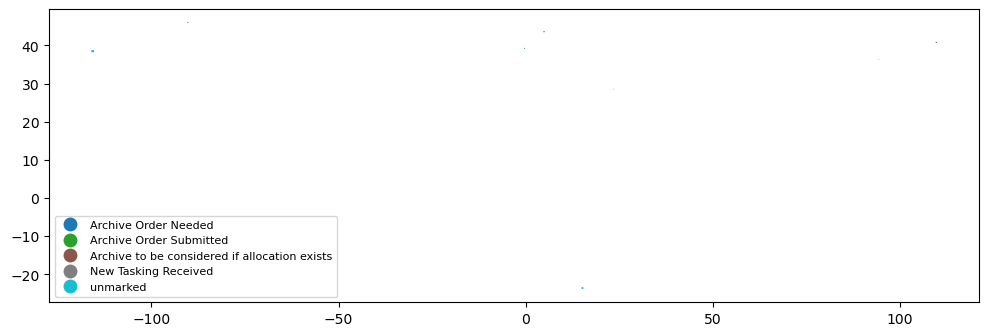

In [19]:
# Footprints of the tracked acquisitions in CSDA (one per acquisition and site); interactive if folium is installed
show = ['site_name', 'acq_num', 'sheet_platform', 'acquisition_id', 'status_TOA', 'status_SR', 'match']
footprints = acq_level[show + ['geometry']].assign(**{c: acq_level[c].astype(str) for c in show})
try:
    import folium
    display(footprints.explore(column='status_TOA', tooltip=show))
except ImportError:
    footprints.plot(column='status_TOA', legend=True, figsize=(12, 6), legend_kwds={'loc': 'lower left', 'fontsize': 8})

### 4d. Summary since September

For images **acquired on or after `SINCE`** at the tracked sites, for the timeline note (section 5 is what changed since the
last run; this is what has arrived over a fixed period):

1. **New in CSDA STAC**: each image is marked if it fills a *New Tasking* request in the sheet (section 4b).
2. **Collected but not in CSDA STAC yet**: not known for Airbus (we have no view of Airbus's own catalog). What we do
   know is how many tasking requests in the sheet are still waiting.

In [20]:
sg = csda.drop(columns='platform').rename(columns={'platform_id': 'platform'})
new_since = (sg.dropna(subset=['acq_time'])
              .groupby(['site_name', 'platform', 'acquisition_id'], as_index=False)
              .agg(acq_time=('acq_time', 'first'), radiometry=('radiometry', lambda r: ', '.join(sorted(r.dropna().unique())))))
new_since = new_since[new_since.acq_time >= pd.Timestamp(SINCE, tz='UTC')].sort_values(['site_name', 'acq_time'])
tasked_ids = set(tracking.loc[tracking.match.eq('new tasking'), 'acquisition_id'])
new_since['fills_tasking_request'] = new_since.acquisition_id.isin(tasked_ids)

# Tasking requests in the sheet: one per TOA / SR cell of a 'New Tasking' slot
task_requests = tracking[tracking.status.isin([NEW_TASKING_STATUS, 'New Tasking Received'])]
by = lambda df: df.groupby('site_name')
since_summary = pd.DataFrame({
    'new_in_csda': by(new_since).size(),
    'with_SR': by(new_since[new_since.radiometry.str.contains('SR')]).size(),
    'fill_tasking_requests': by(new_since[new_since.fills_tasking_request]).size(),
    'tasking_requests': by(task_requests).size(),
    'requests_filled': by(task_requests[task_requests.status == 'New Tasking Received']).size(),
    'requests_waiting': by(task_requests[task_requests.status == NEW_TASKING_STATUS]).size(),
}).reindex(sorted(sites.site_name)).fillna(0).astype(int)
since_summary['platforms'] = by(new_since).platform.agg(lambda p: ', '.join(f"{k} {v}" for k, v in p.value_counts().items()))
since_summary['latest'] = by(new_since).acq_time.max().dt.strftime('%Y-%m-%d')
since_summary.loc['Total'] = since_summary.sum(numeric_only=True)
since_summary = since_summary.astype({c: int for c in since_summary.columns if c not in ('platforms', 'latest')})
since_summary

,new_in_csda,with_SR,fill_tasking_requests,tasking_requests,requests_filled,requests_waiting,platforms,latest
site_name,,,,,,,,
Baotou,11,0,10,11,10,1,"PNEO3 3, PNEO4 3, PHR1B 3, PHR1A 2",2026-11-05
Gobabeb,0,0,0,0,0,0,NaN,NaN
Golmud,2,0,2,17,2,15,"PNEO4 1, PNEO3 1",2026-10-13
La Crau,0,0,0,0,0,0,NaN,NaN
PICS Libya-4,2,0,0,0,0,0,"PHR1B 1, PHR1A 1",2026-09-09
Railroad Valley,2,0,0,0,0,0,"PNEO3 1, PNEO4 1",2026-09-18
Valencia,2,1,2,24,3,21,"PNEO3 1, PNEO4 1",2026-11-05
WLEF,8,6,8,41,14,27,"PNEO3 4, PNEO4 2, PHR1B 1, PHR1A 1",2026-10-24
Total,27,7,22,93,29,64,NaN,NaN


In [21]:
today_ = pd.Timestamp.today().normalize()   # local date
d = lambda t: f"{pd.Timestamp(t):%-m/%-d/%y}"
per_site = lambda x: ', '.join(f"{k} {int(v)}" for k, v in x[x > 0].sort_values(ascending=False).items()) or 'none'
ss = since_summary.drop(index='Total')
n_new = len(new_since)
n_tasked = int(new_since.fills_tasking_request.sum())
quiet = ss[ss.new_in_csda == 0].index
n_req, n_filled, n_wait = len(task_requests), int((task_requests.status == 'New Tasking Received').sum()), int((task_requests.status == NEW_TASKING_STATUS).sum())
plat = ', '.join(f"{k} {v}" for k, v in new_since.platform.value_counts().items())

new_txt = (f"{n_new} Airbus images acquired since {d(SINCE)} are in the CSDA STAC, at {(ss.new_in_csda > 0).sum()} of "
           f"{len(ss)} sites ({per_site(ss.new_in_csda)}; by satellite: {plat}); {int(ss.with_SR.sum())} also have "
           f"surface reflectance. {n_tasked} of them fill tasking requests from the sheet.")
task_txt = (f"Tasking: {n_filled} of the {n_req} tasking requests in the tracking sheet (TOA and SR counted separately) "
            f"are filled; {n_wait} are still waiting ({per_site(ss.requests_waiting)}).")
unknown_txt = "Images Airbus has collected but not yet delivered cannot be counted: we have no view of Airbus's own catalog."
quiet_txt = f"Nothing new since {d(SINCE)} at {', '.join(quiet)}." if len(quiet) else ''
display(Markdown('\n'.join(f"- {t}" for t in [f"**As of {d(today_)}**", new_txt, task_txt, quiet_txt, unknown_txt] if t)))

receive_note = ' '.join(t for t in [
    f"Status {d(today_)} (images acquired since {d(SINCE)} at the {len(ss)} tracked sites).",
    f"New in CSDA STAC: {n_new} images at {(ss.new_in_csda > 0).sum()} sites ({per_site(ss.new_in_csda)}); "
    f"{int(ss.with_SR.sum())} with surface reflectance; {n_tasked} fill tasking requests.",
    f"Tasking requests: {n_filled} of {n_req} filled, {n_wait} still waiting.",
    f"Nothing new at {', '.join(quiet)}." if len(quiet) else '',
    "Collected but not yet delivered: unknown (no access to Airbus's catalog)."] if t)
print(receive_note)

- **As of 11/7/26**
- 27 Airbus images acquired since 9/1/26 are in the CSDA STAC, at 6 of 8 sites (Baotou 11, WLEF 8, Golmud 2, PICS Libya-4 2, Railroad Valley 2, Valencia 2; by satellite: PNEO3 10, PNEO4 8, PHR1B 5, PHR1A 4); 7 also have surface reflectance. 22 of them fill tasking requests from the sheet.
- Tasking: 29 of the 93 tasking requests in the tracking sheet (TOA and SR counted separately) are filled; 64 are still waiting (WLEF 27, Valencia 21, Golmud 15, Baotou 1).
- Nothing new since 9/1/26 at Gobabeb, La Crau.
- Images Airbus has collected but not yet delivered cannot be counted: we have no view of Airbus's own catalog.

Status 11/7/26 (images acquired since 9/1/26 at the 8 tracked sites). New in CSDA STAC: 27 images at 6 sites (Baotou 11, WLEF 8, Golmud 2, PICS Libya-4 2, Railroad Valley 2, Valencia 2); 7 with surface reflectance; 22 fill tasking requests. Tasking requests: 29 of 93 filled, 64 still waiting. Nothing new at Gobabeb, La Crau. Collected but not yet delivered: unknown (no access to Airbus's catalog).


### 4e. Excel copy for colleagues

A copy of the `AirbusTracking` tab with the cells of acquisitions already in CSDA STAC filled green
(pale green = `'same pass?'` match, to check), and both added to the legend (G1, G2). A cell is recoloured
only if CSDA has that column's radiometry (TOA or SR). Values, other colours, borders and the
"CSDA has N scenes" headers are left as they were.

Slots filled with new tasking (section 4b) get the sheet's own *New Tasking Received* legend colour and the CSDA
acquisition ID (e.g. `PNEO3_202610061657285`; for PNeo TOA also the date, as in the archive rows). Reading the new
sheet with `order_tracking.read_airbus_tracking` gives these as `tracking_id` with their acquisition time.

In [22]:
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
stamp = pd.Timestamp.today().strftime('%Y%m%d')
xlsx_out = f'{OUT_DIR}/{Path(TRACKING_XLSX).stem}_{TRACKING_SHEET}_CSDA_STAC_{stamp}.xlsx'
recoloured = order_tracking.write_csda_status(TRACKING_XLSX, xlsx_out, tracking, TRACKING_SHEET)
print(xlsx_out)
recoloured.groupby(['color', 'status']).size()

/explore/nobackup/people/pmontesa/multistac/airbus_order_tracking/OnRamp2_OrderTracking_August2026_AirbusTracking_CSDA_STAC_20261107.xlsx


color                                                  status                                       
In CSDA STAC (as of 2026-11-07)                        Archive Order Needed                              1
                                                       Archive Order Submitted                          64
                                                       Archive to be considered if allocation exists    14
Likely in CSDA STAC (acquisition time differs; check)  Archive Order Submitted                           6
                                                       unmarked                                          2
New Tasking Received                                   New Tasking Received                             29
dtype: int64

## 5. New since the last run

`products.new` = this product was not in the last run's list. `new_acquisition` = no product of this acquisition was.

In [23]:
products, last_run = tracking_report.compare_with_last_run(products, OUT_DIR)
products['wanted'] = True   # every CSDA product at the tracked sites
new = tracking_report.new_table(products)
new

,site_name,acquisition_id,sensor,acq_time,products,new_acquisition,radiometry,on_adapt
0,Baotou,PNEO4_202611020331137,PNEO4,2026-11-02 03:31:13.700000+00:00,2,True,TOA,False
1,Baotou,PHR1B_202611050337084,PHR1B,2026-11-05 03:37:08.400000+00:00,2,True,TOA,False
2,Valencia,PNEO4_202611051057111,PNEO4,2026-11-05 10:57:11.100000+00:00,2,True,TOA,False
3,WLEF,PNEO4_202610091705052,PNEO4,2026-10-09 17:05:05.200000+00:00,4,True,"SR, TOA",False


## 6. HTML summary

The page in `SUMMARY_HTML` is for the SMEs: what is new, what is available, what is on ADAPT, then the products and processing
levels at each site, what is still to come, and what the vendor terms mean. It is rewritten on every run, at the same address, so
the timeline link stays good. Section 8 writes it again after the download. Commit and push it to publish (GitHub Pages).

In [24]:
requests = since_summary.loc[since_summary.tasking_requests > 0, ['tasking_requests', 'requests_filled', 'requests_waiting']]
requests = requests.rename_axis('Site').reset_index().rename(columns={'tasking_requests': 'Tasking requests', 'requests_filled': 'Filled',
                                                                      'requests_waiting': 'Waiting'})
PAGE = dict(
    title='Airbus data in CSDA STAC and on ADAPT',
    intro=f'Every Airbus acquisition in CSDA STAC at the {len(sites)} tracked sites, and what is on ADAPT '
          '(<code>CSDA_eval/Data/Airbus</code>).',
    notes=['<b>Acquisition</b> = one satellite collect (Airbus acquisition / datastrip ID). <b>Products</b> = pan and MS products; '
           'an acquisition delivered with more than one radiometry has more.',
           'An Airbus item ID reads satellite, time, bands, geometry and radiometry: <code>PNEO4_202611051057111_MS-FS_ORT_RFL</code>.'],
    labels=tracking_report.AIRBUS_RADIOMETRY_LABELS, sites=sites.site_name,
    coming=('Tasking requests in the order sheet, counting TOA and SR separately. What Airbus has collected but not delivered is '
            'not known: we have no view of its catalog.', requests),
    other_page=('Vantor Legion', 'legion_augmentation_summary.html'))
tracking_report.write_summary_page(products, SUMMARY_HTML, last_run=last_run, **PAGE)
site_table = tracking_report.site_table(products)
site_table

,Site,Acqs,New,On ADAPT,Products,Products on ADAPT,TOA only,SR only,TOA + SR,Other,Sensors (acqs),Acquired
0,PICS Libya-4,41,0,41,166,164,19,15,7,0,"Pleiades: PHR1A (7), PHR1B (6); Pleiades Neo: ...",2021-08-22 – 2026-09-09
1,La Crau,36,0,36,72,72,36,0,0,0,"Pleiades: PHR1A (8), PHR1B (8); Pleiades Neo: ...",2023-06-28 – 2026-07-28
2,Railroad Valley,35,0,35,70,70,35,0,0,0,"Pleiades: PHR1A (6), PHR1B (8); Pleiades Neo: ...",2023-04-14 – 2026-09-18
3,Gobabeb,32,0,32,64,64,32,0,0,0,"Pleiades: PHR1A (7), PHR1B (6); Pleiades Neo: ...",2016-04-07 – 2026-08-23
4,Baotou,26,2,21,52,42,26,0,0,0,"Pleiades: PHR1A (5), PHR1B (6); Pleiades Neo: ...",2021-08-15 – 2026-11-05
5,Valencia,16,1,15,42,40,11,0,5,0,"Pleiades: PHR1A (5), PHR1B (5); Pleiades Neo: ...",2023-04-25 – 2026-11-05
6,WLEF,9,1,8,30,26,3,0,6,0,"Pleiades: PHR1A (2), PHR1B (1); Pleiades Neo: ...",2023-11-13 – 2026-10-24
7,Golmud,3,0,3,6,6,3,0,0,0,"Pleiades: PHR1A (1); Pleiades Neo: PNEO3 (1), ...",2025-07-06 – 2026-10-13
8,Total,198,4,191,502,484,165,15,18,0,"Pleiades: PHR1A (41), PHR1B (40); Pleiades Neo...",2016-04-07 – 2026-11-05


## 7. Download

Every product in `plan` goes to `DOWNLOAD_DIR/<item id>/`: Earthdata login from `credentials.ini`, then `CsdaClient` and
`csdalib_download.download_all_assets` in a thread pool. Files already there are kept, so re-running resumes an interrupted
download. `PRODUCTS_CSV`, next to the data, says which site and acquisition each product belongs to.

In [25]:
plan = tracking_report.plan_download(products, res.items)
print(f"{len(plan)} products to download ({plan.GB.sum():.1f} GB), {plan.acquisition_id.nunique()} acquisitions")
plan.groupby(['site_name', 'sensor']).agg(acquisitions=('acquisition_id', 'nunique'), products=('id', 'size'), GB=('GB', 'sum')).round(2)

18 products to download (40.7 GB), 8 acquisitions


acquisitions  products     GB
site_name    sensor                               
Baotou       PHR1B              1         2   1.28
             PNEO3              2         4  10.63
             PNEO4              2         4  12.16
PICS Libya-4 PNEO3              1         2   6.40
Valencia     PNEO4              1         2   3.37
WLEF         PNEO4              1         4   6.88

In [26]:
check = tracking_report.download(plan, res.items, products, DOWNLOAD_DIR, PRODUCTS_CSV, CREDENTIALS_FILE,
                                 do_download=DO_DOWNLOAD, download_all=DOWNLOAD_ALL, max_workers=MAX_WORKERS)
check[~check.complete] if check is not None else None

Auth: Hello montesano, you have a valid token!


Quota table unavailable: 1 validation error for Profile
nda_signed
  Field required [type=missing, input_value={'earthdata_us


  ✓ metadata              → DIM_PNEO3_STD_202610260345582_PAN_ORT_PWOI_000727294_1_2_F_1.XML
  ✓ metadata              → DIM_PNEO3_STD_202203310331287_PAN_ORT_PWOI_000635326_1_1_F_1.XML
  ✓ metadata              → DIM_PNEO4_STD_202611020331144_PAN_ORT_PWOI_000727308_1_2_F_1.XML
  ✓ metadata              → DIM_PNEO4_STD_202210120331192_PAN_ORT_PWOI_000635342_1_1_F_1.XML


  ✓ metadata              → DIM_PNEO4_STD_202210120331192_MS-FS_ORT_PWOI_000635342_1_1_F_1.XML
  ✓ metadata              → DIM_PNEO4_STD_202611020331144_MS-FS_ORT_PWOI_000727308_1_2_F_1.XML
  ✓ metadata              → DIM_PNEO3_STD_202203310331287_MS-FS_ORT_PWOI_000635326_1_1_F_1.XML
  ✓ metadata              → DIM_PNEO3_STD_202610260345582_MS-FS_ORT_PWOI_000727294_1_2_F_1.XML


  ✓ thumbnail             → PREVIEW_PNEO4_STD_202210120331192_MS-FS_ORT_PWOI_000635342_1_1_F_1.JPG
  ✓ thumbnail             → PREVIEW_PNEO4_STD_202210120331192_PAN_ORT_PWOI_000635342_1_1_F_1.JPG
  ✓ thumbnail             → PREVIEW_PNEO4_STD_202611020331144_PAN_ORT_PWOI_000727308_1_2_F_1.JPG
  ✓ thumbnail             → PREVIEW_PNEO3_STD_202610260345582_PAN_ORT_PWOI_000727294_1_2_F_1.JPG
  ✓ thumbnail             → PREVIEW_PNEO4_STD_202611020331144_MS-FS_ORT_PWOI_000727308_1_2_F_1.JPG
  ✓ thumbnail             → PREVIEW_PNEO3_STD_202203310331287_PAN_ORT_PWOI_000635326_1_1_F_1.JPG
  ✓ thumbnail             → PREVIEW_PNEO3_STD_202610260345582_MS-FS_ORT_PWOI_000727294_1_2_F_1.JPG
  ✓ thumbnail             → PREVIEW_PNEO3_STD_202203310331287_MS-FS_ORT_PWOI_000635326_1_1_F_1.JPG


  ✓ auxiliary_0           → PROCESSING_PNEO4_STD_202611020331144_MS-FS_ORT_PWOI_000727308_1_2_F_1.XML
  ✓ auxiliary_0           → PROCESSING_PNEO4_STD_202611020331144_PAN_ORT_PWOI_000727308_1_2_F_1.XML
  ✓ auxiliary_0           → PROCESSING_PNEO4_STD_202210120331192_MS-FS_ORT_PWOI_000635342_1_1_F_1.XML
  ✓ auxiliary_0           → PROCESSING_PNEO3_STD_202203310331287_PAN_ORT_PWOI_000635326_1_1_F_1.XML
  ✓ auxiliary_0           → PROCESSING_PNEO4_STD_202210120331192_PAN_ORT_PWOI_000635342_1_1_F_1.XML
  ✓ auxiliary_0           → PROCESSING_PNEO3_STD_202203310331287_MS-FS_ORT_PWOI_000635326_1_1_F_1.XML
  ✓ auxiliary_0           → PROCESSING_PNEO3_STD_202610260345582_PAN_ORT_PWOI_000727294_1_2_F_1.XML
  ✓ auxiliary_0           → PROCESSING_PNEO3_STD_202610260345582_MS-FS_ORT_PWOI_000727294_1_2_F_1.XML


... (180 outputs left out)

  ✓ area-of-interest-mask  → ROI_PNEO4_STD_202210120331192_PAN_ORT_PWOI_000635342_1_1_F_1.GML
Successfully processed: PNEO4_202210120331184_PAN_ORT_RFL


  ✓ visual-r2c2           → IMG_PNEO3_STD_202602250907500_PAN_ORT_PWOI_000501715_1_1_F_1_P_R2C2.TIF


  ✓ area-of-interest-mask  → ROI_PNEO3_STD_202602250907500_PAN_ORT_PWOI_000501715_1_1_F_1.GML
Successfully processed: PNEO3_202602250907490_PAN_ORT_RFL


,id,assets,files_on_disk,complete


## 8. Results

What is on ADAPT after the download, the page, this run's list for next time, and the three results.

In [27]:
products = tracking_report.mark_on_adapt(products, res.items, ALREADY_HAVE_DIRS, local_copies)
tracking_report.write_summary_page(products, SUMMARY_HTML, last_run=last_run, plan=plan, check=check, download_dir=DOWNLOAD_DIR, **PAGE)
tracking_report.save_run(products, OUT_DIR, res.log)
display(Markdown(tracking_report.results(VENDOR, products, last_run, SUMMARY_HTML, plan, check, DO_DOWNLOAD)))

**Airbus, as of 11/7/26**

1. New in CSDA STAC since the last run (11/3/26): 4 acquisitions (10 products: Baotou 4, WLEF 4, Valencia 2).
2. HTML summary updated: `/home/pmontesa/code/csda_summaries/html/augmentation/airbus_augmentation_summary.html`. CSDA STAC has 198 acquisitions at 8 sites; 198 are on ADAPT (502 of 502 products).
3. Download: 18 of 18 products complete (40.7 GB). Rerun `footprint_CSDA_eval_all_data.ipynb` to add them to the footprints.